# Paper figures and tables
Run from the repository root or this folder. The shared implementation is in `plot_helpers.py`; see `../README.md` for input provenance and missing appendix inputs.
The default comparison uses the paper-specified **joint_attributes** specialist. Measured Gaussian NLL uses test-image bootstrap intervals; proxy moment uncertainty is a separate quantity.


In [7]:
from pathlib import Path
import sys
from IPython.display import display

# Set MIB_REPO_ROOT when launching from outside the repository.
import os
if os.environ.get("MIB_REPO_ROOT"):
    REPO_ROOT = Path(os.environ["MIB_REPO_ROOT"]).expanduser().resolve()
else:
    REPO_ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
                      if (p / "paper_plotting" / "plot_helpers.py").is_file()
                      and (p / "celeba_experiment").is_dir()
                      and (p / "dsprites_experiment").is_dir()), None)
if REPO_ROOT is None or not (REPO_ROOT / "paper_plotting" / "plot_helpers.py").is_file():
    raise RuntimeError("Set MIB_REPO_ROOT to the repository root.")
sys.path.insert(0, str(REPO_ROOT))

OUTPUT = REPO_ROOT / "paper_plotting" / "paper_figures"
CELEBA_RUN = REPO_ROOT / "celeba_experiment" / "runs" / "robust_rate_selection"
DSPRITES_CSV = REPO_ROOT / "dsprites_experiment" / "runs" / "dsprites_1" / "summary" / "all_runs.csv"
SPECIALIST = "joint_attributes"
GENERALIST = "reconstruction"
ORACLE = "task_aware"
MIXTURE = None
GAUSSIAN_METRIC = "measured"
GAUSSIAN_NPZ = None
CODES_NPZ = None
FINETUNED_RUN = None
ROLE_SWAP_CSV = REPO_ROOT / "dsprites_experiment" / "runs" / "dsprites_role_swap" / "summary" / "selected_runs.csv"
NULL_CONTROL_CSV = REPO_ROOT / "dsprites_experiment" / "runs" / "dsprites_null_control" / "summary" / "selected_runs.csv"
WHITENED_COVARIANCE_NPY = None
SHRINKAGE_CSV = None
WORST_CASE_CSV = None
SNR_SWEEP_CSV = None
DSPRITES_FILTERS = {}
TABLE_BETAS = [0.4, 0.3, 0.2, 0.15, 0.1, 0.05]
MAIN_RATE_LIMITS = (0, 10)
OUTPUT.mkdir(parents=True, exist_ok=True)


## Plotting and estimator definitions
Execute this cell once. Colors can be changed in `COLORS` to match the theoretical figures.

In [8]:
from paper_plotting.plot_helpers import *


## Figure 3, CelebA appendix, and theory-to-data table
The task-aware Gaussian curve appears only on the left. Rank heatmaps remain in the appendix to preserve readable difference panels. Per-run code-usage histograms are exported as a multipage vector PDF. Measured-NLL bands and proxy moment-refitting bands are distinct; the proxy asymptote is not a measured-NLL floor.


\begin{tabular}{llllll}
\toprule
panel & kendall\_tau\_b & reversed\_pairs & comparable\_untied\_pairs & total\_pairs & max\_rank\_change \\
\midrule
gaussian & 0.357143 & 9 & 28 & 28 & 6 \\
codes & 0.0714286 & 13 & 28 & 28 & 4 \\
\bottomrule
\end{tabular}

\begin{tabular}{llllllll}
\toprule
panel & point & roots & n\_draws & crossing\_fraction & conditional\_median & conditional\_ci & multiple\_crossings \\
\midrule
gaussian & 16.8182 & [16.818155915239572] & 2000 & 1 & 16.8207 & [14.647871627955585, 19.42407400951424] & 0 \\
codes & 21.2035 & [21.2034588150751] & 2000 & 1 & 21.1762 & [16.32148022196372, 25.01281799932733] & 0 \\
\bottomrule
\end{tabular}

\begin{tabular}{ll}
\toprule
Quantity & Value \\
\midrule
SNR: Smiling & 0.41476 \\
SNR: Eyeglasses & 0.737435 \\
SNR: Blond\_Hair & 0.884189 \\
SNR: Young & 0.375638 \\
d & 32 \\
k & 5 \\
Delta & 0.0181922 \\
D\_miss (bits) & 0.215195 \\
Sufficient rate bound (bits) & 16.2447 \\
gaussian observed crossover / conditional CI & 16.818

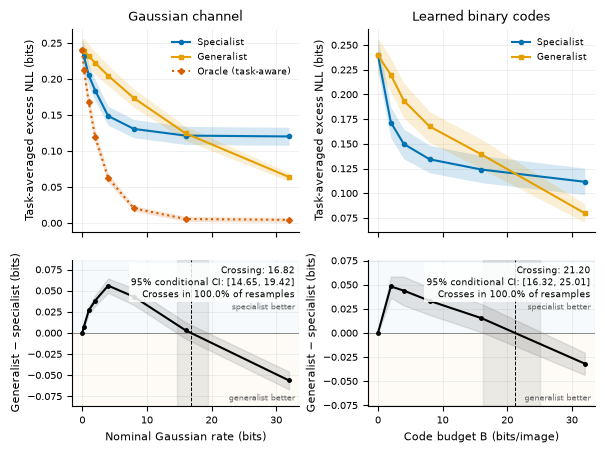

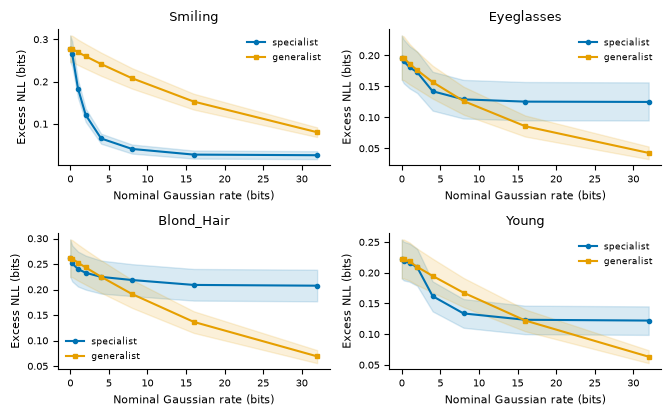

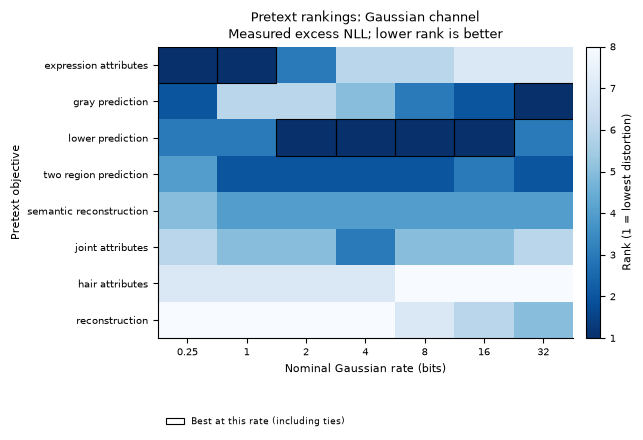

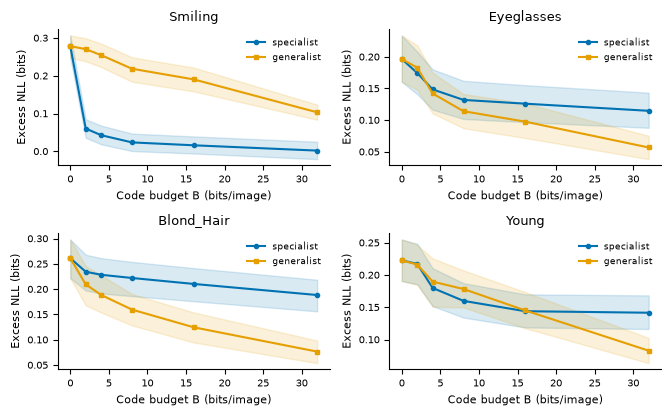

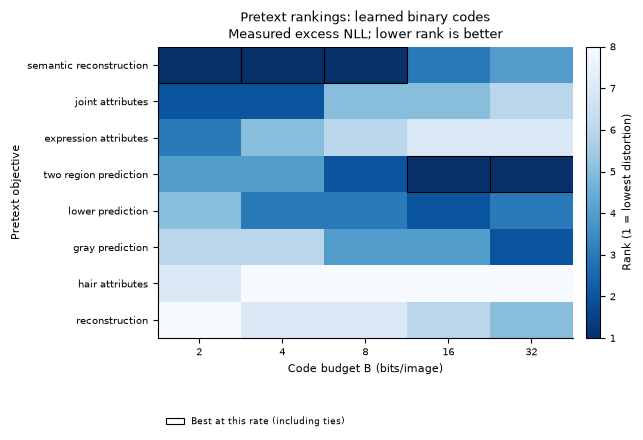

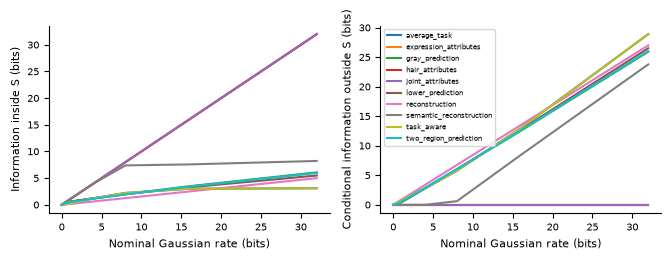

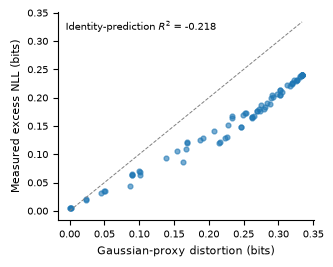

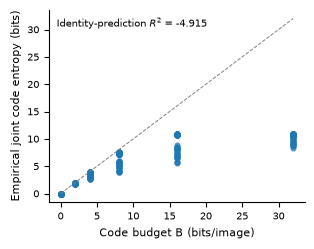

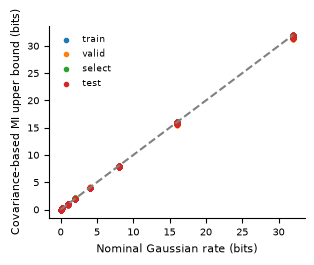

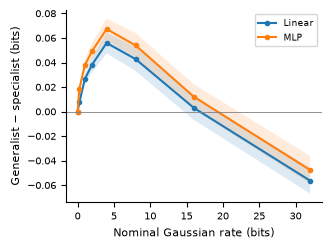

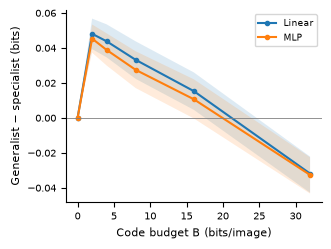

In [9]:
if CELEBA_RUN is not None:
    celeba_crossovers = run_main(CELEBA_RUN, OUTPUT/"celeba", SPECIALIST,
        GENERALIST, MIXTURE, GAUSSIAN_METRIC, GAUSSIAN_NPZ, CODES_NPZ, oracle=ORACLE)
else:
    print("CelebA not supplied: set CELEBA_RUN and verify SPECIALIST before running this cell.")


## dSprites: Figure 4 and Table 1
The canonical `inputs/dsprites_all_runs.csv` has 14 settings, 3 seeds, and 4 objectives. Indices are computed per seed before averaging. The six selected table rows include the observed 6.19-bit setting. Error bars show seed ranges.


\begin{tabular}{lllll}
\toprule
$\mathcal R_{\mathrm{VIB}}$ & $\mathcal I_{\mathrm{common}}$ & $\mathcal I_{\mathrm{precise}}$ & Gap & $\sum_i\mathcal I_i$ \\
\midrule
1.75 & 1.85 & 0.00 & 1.84 & 1.85 \\
2.16 & 2.27 & 0.00 & 2.27 & 2.27 \\
5.10 & 2.71 & 2.62 & \textbf{0.09} & 5.34 \\
6.19 & 2.96 & 3.47 & \textbf{-0.52} & 6.43 \\
7.15 & 3.29 & 4.03 & -0.75 & 7.32 \\
8.38 & 3.74 & 4.62 & -0.87 & 8.36 \\
\bottomrule
\end{tabular}

\begin{tabular}{lllllll}
\toprule
beta & seed & rate\_kl\_bits & I\_common & I\_precise & gap & sum\_I \\
\midrule
0.8 & 0 & 0.00040635 & 0.00158157 & 0.00632618 & -0.00474461 & 0.00790775 \\
0.4 & 0 & 1.74137 & 1.83193 & 0.00562793 & 1.82631 & 1.83756 \\
0.3 & 0 & 2.14076 & 2.25509 & 0.0056824 & 2.24941 & 2.26078 \\
0.2 & 0 & 5.03784 & 2.69003 & 2.58031 & 0.109717 & 5.27034 \\
0.15 & 0 & 6.15462 & 2.93528 & 3.45119 & -0.515908 & 6.38647 \\
0.1 & 0 & 7.15073 & 3.31114 & 4.02299 & -0.711849 & 7.33414 \\
0.05 & 0 & 8.35091 & 3.71325 & 4.64986 & -0.93661 & 8.36311 

,rate_kl_bits,I_common,I_precise,gap,sum_I
beta,,,,,
0.8000,0.001,-0.003,0.004,-0.007,0.001
0.4000,1.755,1.845,0.004,1.842,1.849
0.3000,2.155,2.269,0.004,2.265,2.273
0.2000,5.100,2.715,2.624,0.091,5.339
0.1500,6.195,2.955,3.472,-0.517,6.427
0.1000,7.147,3.288,4.034,-0.747,7.322
0.0500,8.384,3.742,4.616,-0.875,8.358
0.0200,9.766,4.260,5.065,-0.805,9.324
0.0100,10.968,4.567,5.275,-0.709,9.842


{
  "labels": [
    "Common",
    "Precise"
  ],
  "gap_definition": "Common \u2212 precise (bits)",
  "crossing_direction": 1,
  "seed_range_contains_zero_by_beta": null,
  "predicted_gaussian_reference": 5.299560281858908,
  "observed_mean_roots": [
    5.263820652428514
  ],
  "per_seed_roots": {
    "0": [
      5.233691090627798
    ],
    "1": [
      5.243245622253535
    ],
    "2": [
      5.314365523471686
    ]
  },
  "reversing_seeds": 3,
  "n_seeds": 3,
  "n_betas": 14,
  "weights": [
    0.75,
    0.25
  ],
  "snrs": [
    16,
    256
  ],
  "rate_grid_means": [
    0.0005592262605204667,
    1.754801074663798,
    2.155064264933268,
    5.100431442260742,
    6.1949717203776045,
    7.147473653157552,
    8.383719126383463,
    9.766174952189127,
    10.967873891194662,
    12.149190902709961,
    15.861197471618652,
    19.045685450236004,
    22.881588617960613,
    36.31947326660157
  ],
  "max_index_excess": 0.2470471840094044
}


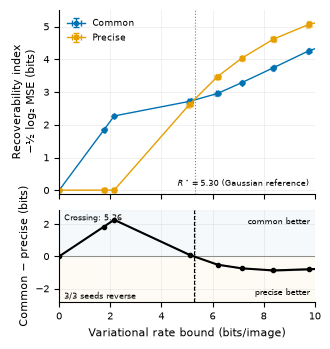

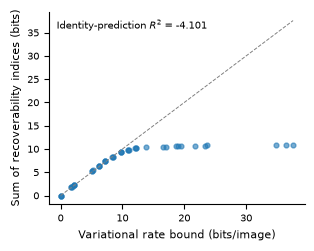

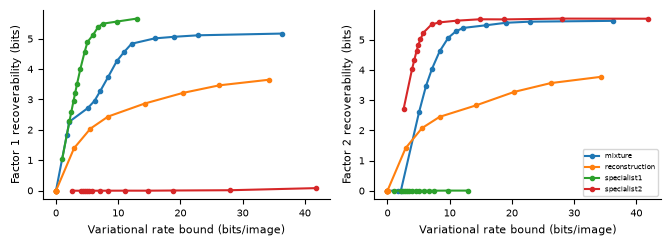

In [4]:
if DSPRITES_CSV.exists():
    ds_rows, ds_means, ds_summary = dsprites(DSPRITES_CSV, OUTPUT/"dsprites",
        filters=DSPRITES_FILTERS, table_betas=TABLE_BETAS, main_xlim=MAIN_RATE_LIMITS)
    display(ds_means.round(3))
    print(json.dumps(ds_summary, indent=2))
    dsprites_context(DSPRITES_CSV, OUTPUT/"dsprites")
else:
    print("Set DSPRITES_CSV to the supplied all_runs CSV.")


## Optional appendix inputs
The control configurations and commands are documented in `README.md`. Paths default to their completed, validation-selected summaries. Missing inputs are listed explicitly. The role-swap gap holds physical identities fixed (horizontal minus vertical), so its expected crossing direction is negative-to-positive. No reversal or null result is enforced.


\begin{tabular}{lllll}
\toprule
$\mathcal R_{\mathrm{VIB}}$ & Horizontal index & Vertical index & Horizontal - vertical & $\sum_i\mathcal I_i$ \\
\midrule
0.00 & -0.00 & 0.00 & -0.01 & 0.00 \\
1.77 & -0.00 & 1.86 & -1.87 & 1.86 \\
2.14 & -0.00 & 2.26 & -2.26 & 2.25 \\
5.15 & 2.68 & 2.70 & \textbf{-0.02} & 5.39 \\
6.16 & 3.45 & 2.95 & \textbf{0.49} & 6.40 \\
7.14 & 4.03 & 3.30 & 0.74 & 7.33 \\
8.43 & 4.62 & 3.79 & 0.83 & 8.41 \\
9.85 & 5.10 & 4.26 & 0.84 & 9.36 \\
11.02 & 5.31 & 4.58 & 0.73 & 9.89 \\
12.35 & 5.43 & 4.78 & 0.64 & 10.21 \\
17.14 & 5.50 & 4.94 & 0.56 & 10.43 \\
21.58 & 5.58 & 5.06 & 0.52 & 10.65 \\
27.29 & 5.62 & 5.10 & 0.52 & 10.72 \\
37.92 & 5.65 & 5.19 & 0.46 & 10.85 \\
\bottomrule
\end{tabular}

\begin{tabular}{lllllll}
\toprule
beta & seed & rate\_kl\_bits & I\_horizontal & I\_vertical & gap & sum\_I \\
\midrule
0.8 & 0 & 0.00109005 & 0.00138368 & 0.00693281 & -0.00554913 & 0.00831649 \\
0.4 & 0 & 1.76827 & 0.00111815 & 1.86014 & -1.85902 & 1.86126 \\
0.3 & 0 & 2.1222

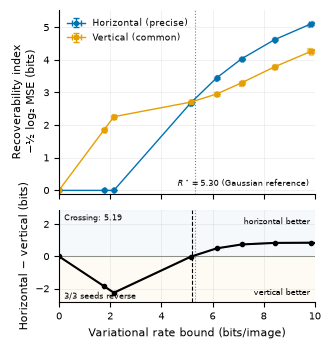

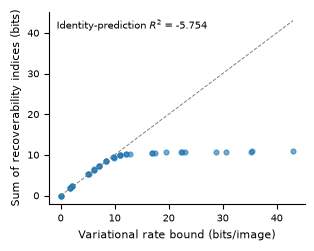

In [5]:
missing_inputs = []
for control, source in [("role_swap", ROLE_SWAP_CSV), ("null_control", NULL_CONTROL_CSV)]:
    if source is not None and Path(source).is_file():
        dsprites_control(source, OUTPUT/control, control, main_xlim=MAIN_RATE_LIMITS)
    else:
        missing_inputs.append(f"{control}: {source} (requires new training)")
for label, source in [("whitening spectrum", WHITENED_COVARIANCE_NPY),
                      ("shrinkage sensitivity", SHRINKAGE_CSV),
                      ("constructed worst case", WORST_CASE_CSV),
                      ("SNR-cap sweep", SNR_SWEEP_CSV),
                      ("fine-tuned replication", FINETUNED_RUN)]:
    if source is None:
        missing_inputs.append(f"{label}: input not configured")
(OUTPUT/"missing_figure_inputs.txt").write_text("\n".join(missing_inputs)+"\n")
print("\n".join(missing_inputs))
if WHITENED_COVARIANCE_NPY is not None:
    whitening_plot(WHITENED_COVARIANCE_NPY, OUTPUT/"diagnostics", SHRINKAGE_CSV)
if WORST_CASE_CSV is not None:
    worst_case(WORST_CASE_CSV, OUTPUT/"worst_case", SNR_SWEEP_CSV)
if FINETUNED_RUN is not None:
    run_main(FINETUNED_RUN, OUTPUT/"finetuned", SPECIALIST, GENERALIST, MIXTURE, GAUSSIAN_METRIC, oracle=ORACLE)


## Output inventory
Outputs include vector PDFs, PNG previews, tables, crossover summaries, and explicit selected-pair provenance. See `../README.md` for missing inputs and manuscript differences.


In [6]:
files=sorted(OUTPUT.rglob("*.tex"))
print("LaTeX tables:")
for path in files: print(path)
print("\nPDF figures:")
for path in sorted(OUTPUT.rglob("*.pdf")): print(path)


LaTeX tables:
/home2/ngstiles/projects/multitask_information_bottleneck/paper_plotting/paper_figures/celeba/fig3_crossovers.tex
/home2/ngstiles/projects/multitask_information_bottleneck/paper_plotting/paper_figures/celeba/fig3_rank_instability.tex
/home2/ngstiles/projects/multitask_information_bottleneck/paper_plotting/paper_figures/celeba/proxy_fidelity_score.tex
/home2/ngstiles/projects/multitask_information_bottleneck/paper_plotting/paper_figures/celeba/theory_to_data.tex
/home2/ngstiles/projects/multitask_information_bottleneck/paper_plotting/paper_figures/dsprites/fig4_all_settings.tex
/home2/ngstiles/projects/multitask_information_bottleneck/paper_plotting/paper_figures/dsprites/fig4_per_seed.tex
/home2/ngstiles/projects/multitask_information_bottleneck/paper_plotting/paper_figures/dsprites/fig4_table.tex
/home2/ngstiles/projects/multitask_information_bottleneck/paper_plotting/paper_figures/role_swap/role_swap_all_settings.tex
/home2/ngstiles/projects/multitask_information_bottle